# 02 · Demand forecast: trips by zone and hour, four weeks ahead

**Question.** How many trips will each zone have in each hour of the next four weeks? Operations
uses this to plan driver incentives and supply; the pay policy (phase 6) uses it to know where
drivers will be short.

**Setup**
* Target: completed trips per zone per hour (completed trips stand in for requests; the TLC
  records have no unfulfilled requests).
* **Forecast origins** are Mondays 00:00. From each origin we forecast every hour of the next
  four weeks, using only data before the origin (a *direct* multi-horizon model). A lag of one
  week can't be used for a target three weeks out, so features are calendar facts, holidays and
  summaries of history up to the origin (same hour last week, mean of the same hour over the
  last four weeks, recent level, the same hour a year earlier).
* **Baselines to beat:** *seasonal naive* (same hour last week, repeated) and the *four-week
  mean* of the same hour of week. A model that can't beat these isn't worth running.
* **Backtest:** rolling origin. The last four 4-week windows are the test; for each, the model is
  trained only on origins whose targets ended before that window starts. Hyperparameters are
  chosen on the window *before* the first test window, never on the test.
* Metrics: weighted MAPE (Σ|error| ÷ Σ trips) and bias, at the zone × hour level and at the
  coarser levels planning actually uses (zone × day, cluster × hour).

In [1]:
import time

import lightgbm as lgb
import numpy as np
import pandas as pd

from ridepay import data, forecast, plots
from ridepay.records import show_verdict, write_metrics

SOURCE = data.source()
FAST = SOURCE != "real"          # CI smoke run on the synthetic city: two settings instead of four
con = data.connect()
clusters = data.load_table("zone_clusters")
use = clusters[clusters["cluster_name"] != "Sparse"]
zone_cluster = dict(zip(use["zone"], use["cluster"]))
cluster_name = dict(zip(use["cluster"], use["cluster_name"]))
zh = con.sql("SELECT zone, hour, trips FROM zone_hour").df()
panel = forecast.make_panel(zh, zones=list(zone_cluster))
hourly_total = panel.trips.sum(axis=0)
gaps = int((hourly_total == 0).sum())
print(f"source {SOURCE}: {len(panel.zones)} zones x {len(panel.hours):,} hours "
      f"({panel.hours[0]:%Y-%m-%d} to {panel.hours[-1]:%Y-%m-%d}); citywide hours with zero trips: {gaps}")
assert gaps <= 2, "a month is missing from the panel: rebuild before forecasting"   # DST spring-forward hours only

source real: 257 zones x 13,128 hours (2024-01-01 to 2025-06-30); citywide hours with zero trips: 0


## Origins and the backtest windows

In [2]:
H = forecast.HORIZON_H
first = (panel.hours[0] + pd.Timedelta(weeks=4)).normalize()
first += pd.Timedelta(days=(7 - first.dayofweek) % 7)
last = panel.hours[-1] - pd.Timedelta(hours=H - 1)
mondays = pd.date_range(first, last, freq="W-MON")
test_origins = [mondays[-1] - pd.Timedelta(weeks=4 * i) for i in range(4)][::-1]
valid_origin = test_origins[0] - pd.Timedelta(weeks=4)
print("validation window:", valid_origin.date(), "| test windows:", [str(t.date()) for t in test_origins])
hol = forecast.holiday_dates(sorted({panel.hours[0].year, panel.hours[-1].year}))
FEATURES = ["zone", "cluster", "how", "hod", "dow", "month", "horizon_h", "holiday", "day_before_holiday",
            "day_after_holiday", "prof4", "last1", "level_ratio", "zone_week_trips", "year_ago"]
CATEGORICAL = ["zone", "cluster"]


def frame(origin):
    return forecast.features_at_origin(panel, origin, hol, zone_cluster)


def training_rows(cutoff, frac=0.3, seed=0):
    """Rows from every second origin whose four-week target window ends before `cutoff`."""
    origins = [o for o in mondays[::2] if o + pd.Timedelta(hours=H) <= cutoff]
    parts = [frame(o).sample(frac=frac, random_state=seed + i) for i, o in enumerate(origins)]
    return pd.concat(parts, ignore_index=True), origins


def fit(train, params, valid=None, rounds=2000):
    ds = lgb.Dataset(train[FEATURES], train["y"], categorical_feature=CATEGORICAL, free_raw_data=False)
    p = {"objective": "poisson", "verbose": -1, "num_threads": 2, "feature_fraction": 0.9,
         "bagging_fraction": 0.8, "bagging_freq": 1, "seed": 0, **params}
    if valid is None:
        return lgb.train(p, ds, num_boost_round=rounds)
    dv = lgb.Dataset(valid[FEATURES], valid["y"], categorical_feature=CATEGORICAL, reference=ds)
    return lgb.train(p, ds, num_boost_round=rounds, valid_sets=[dv],
                     callbacks=[lgb.early_stopping(50, verbose=False)])

validation window: 2025-02-10 | test windows: ['2025-03-10', '2025-04-07', '2025-05-05', '2025-06-02']


## Tuning on the validation window

Four settings, from small, fast trees to larger, slower ones; early stopping picks the number of
trees. The chosen setting and tree count are then fixed for every test window.

In [3]:
train_v, origins_v = training_rows(valid_origin)
valid = frame(valid_origin)
grid = [{"num_leaves": 31, "learning_rate": 0.1, "min_data_in_leaf": 200},
        {"num_leaves": 127, "learning_rate": 0.1, "min_data_in_leaf": 200},
        {"num_leaves": 63, "learning_rate": 0.05, "min_data_in_leaf": 500},
        {"num_leaves": 255, "learning_rate": 0.05, "min_data_in_leaf": 500}]
tuning = []
for params in (grid[:2] if FAST else grid):
    t0 = time.time()
    m = fit(train_v, params, valid)
    tuning.append({**params, "trees": m.best_iteration,
                   "valid_wmape": forecast.wmape(valid["y"], m.predict(valid[FEATURES], num_iteration=m.best_iteration)),
                   "seconds": round(time.time() - t0)})
tuning = pd.DataFrame(tuning)
best = tuning.loc[tuning["valid_wmape"].idxmin()]
BEST = {k: best[k] for k in ["num_leaves", "learning_rate", "min_data_in_leaf"]}
BEST = {"num_leaves": int(BEST["num_leaves"]), "learning_rate": float(BEST["learning_rate"]),
        "min_data_in_leaf": int(BEST["min_data_in_leaf"])}
TREES = int(best["trees"])
print(f"{len(train_v):,} training rows from {len(origins_v)} origins; validation baseline wmape: "
      f"seasonal naive {forecast.wmape(valid['y'], valid['last1']):.3f}, 4-week mean {forecast.wmape(valid['y'], valid['prof4']):.3f}")
tuning.round(4)

1,347,086 training rows from 26 origins; validation baseline wmape: seasonal naive 0.159, 4-week mean 0.125


,num_leaves,learning_rate,min_data_in_leaf,trees,valid_wmape,seconds
0,31,0.10,200,92,0.1257,13
1,127,0.10,200,81,0.1309,16
2,63,0.05,500,177,0.1277,24
3,255,0.05,500,169,0.1303,36


## Rolling-origin backtest

In [4]:
results, preds = [], []
for origin in test_origins:
    train, _ = training_rows(origin)
    model = fit(train, BEST, rounds=TREES)
    test = frame(origin)
    test["model"] = model.predict(test[FEATURES])
    preds.append(test)
    for name in ["model", "last1", "prof4"]:
        results.append({"origin": origin.date(), "method": name,
                        "wmape_zone_hour": forecast.wmape(test["y"], test[name]),
                        "bias": forecast.bias(test["y"], test[name])})
preds = pd.concat(preds, ignore_index=True)
backtest = pd.DataFrame(results).pivot(index="origin", columns="method", values=["wmape_zone_hour", "bias"])
backtest.round(4)

wmape_zone_hour                    bias                
method               last1   model   prof4   last1   model   prof4
origin                                                            
2025-03-10          0.1542  0.1314  0.1342  0.0303  0.0553  0.0502
2025-04-07          0.1479  0.1195  0.1215  0.0020 -0.0176 -0.0106
2025-05-05          0.1614  0.1290  0.1408 -0.0034 -0.0249 -0.0158
2025-06-02          0.1909  0.1297  0.1385 -0.0269  0.0022  0.0115

In [5]:
LABELS = {"model": "LightGBM", "last1": "Seasonal naive (last week)", "prof4": "4-week mean"}
preds["date"] = preds["hour"].dt.normalize()


def level_wmape(df, keys):
    g = df.groupby(keys)[["y", "model", "last1", "prof4"]].sum()
    return {LABELS[m]: forecast.wmape(g["y"], g[m]) for m in ["model", "last1", "prof4"]}


levels = pd.DataFrame({
    "zone × hour": level_wmape(preds, ["zone", "hour"]),
    "zone × day": level_wmape(preds, ["zone", "date"]),
    "cluster × hour": level_wmape(preds, ["cluster", "hour"]),
    "city × hour": level_wmape(preds, ["hour"]),
}).T
bias_all = {LABELS[m]: forecast.bias(preds["y"], preds[m]) for m in ["model", "last1", "prof4"]}
print("Weighted MAPE over all four test windows:")
levels.round(4)

Weighted MAPE over all four test windows:


,LightGBM,Seasonal naive (last week),4-week mean
zone × hour,0.1274,0.1636,0.1338
zone × day,0.0670,0.0784,0.0701
cluster × hour,0.0667,0.0861,0.0719
city × hour,0.0569,0.0721,0.0621


**How close to the floor?** Hourly counts in a zone are random even when the rate is known exactly:
with Poisson arrivals at rate λ the expected absolute error of a *perfect* forecast is
2 λ^(⌊λ⌋+1) e^(−λ) / ⌊λ⌋!. Summing that over every zone-hour (using the model's prediction as λ)
gives the weighted MAPE no model can beat at this level.

In [6]:
from scipy.special import gammaln  # noqa: E402

lam = np.clip(preds["model"].to_numpy(), 1e-6, None)
k = np.floor(lam)
mad = 2 * np.exp((k + 1) * np.log(lam) - lam - gammaln(k + 1))
noise_floor = float(mad.sum() / preds["y"].sum())
print(f"Poisson noise floor for zone × hour weighted MAPE: {noise_floor:.1%} "
      f"(model {levels.loc['zone × hour', 'LightGBM']:.1%}, 4-week mean {levels.loc['zone × hour', '4-week mean']:.1%})")

Poisson noise floor for zone × hour weighted MAPE: 6.8% (model 12.7%, 4-week mean 13.4%)


,LightGBM,Seasonal naive (last week),trips_share
cluster,,,
Core,0.1230,0.1604,0.4893
Long waits,0.4554,0.5014,0.0056
Commuter residential,0.1244,0.1593,0.4661
Airports,0.1723,0.2090,0.0390


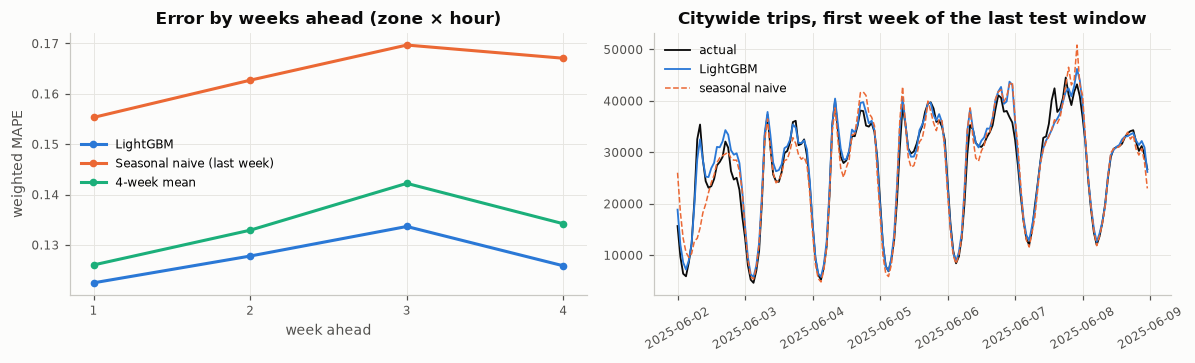

In [7]:
preds["week_ahead"] = preds["horizon_h"] // (7 * 24) + 1
by_week = preds.groupby("week_ahead").apply(
    lambda g: pd.Series({LABELS[m]: forecast.wmape(g["y"], g[m]) for m in ["model", "last1", "prof4"]}),
    include_groups=False)
by_cluster = preds.groupby("cluster").apply(
    lambda g: pd.Series({**{LABELS[m]: forecast.wmape(g["y"], g[m]) for m in ["model", "last1"]},
                         "trips_share": g["y"].sum() / preds["y"].sum()}), include_groups=False)
by_cluster.index = by_cluster.index.map(cluster_name)
fig, axes = plots.subplots(1, 2, figsize=(11, 3.4))
for i, col in enumerate(by_week.columns):
    axes[0].plot(by_week.index, by_week[col], marker="o", ms=4, color=plots.SERIES[i], label=col)
axes[0].set(title="Error by weeks ahead (zone × hour)", xlabel="week ahead", ylabel="weighted MAPE")
axes[0].set_xticks([1, 2, 3, 4])
axes[0].legend()
day = preds[preds["origin"] == preds["origin"].max()].groupby("hour")[["y", "model", "last1"]].sum()
day = day.iloc[: 7 * 24]
axes[1].plot(day.index, day["y"], color=plots.INK, lw=1.2, label="actual")
axes[1].plot(day.index, day["model"], color=plots.SERIES[0], lw=1.2, label="LightGBM")
axes[1].plot(day.index, day["last1"], color=plots.SERIES[1], lw=1, ls="--", label="seasonal naive")
axes[1].set(title="Citywide trips, first week of the last test window")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()
fig.tight_layout()
data.savefig(fig, "02_forecast_backtest")
by_cluster.round(4)

## Holidays: where a calendar-aware model earns its keep

Seasonal naive repeats last week, so on a public holiday (or the week after one) it is wrong by
construction. The year-ago feature and the holiday flags let the model anticipate them.

In [8]:
hol_rows = preds[preds["holiday"] == 1]
holiday_table = (hol_rows.groupby("date")[["y", "model", "last1", "prof4"]].sum()
                 .assign(model_err=lambda d: d["model"] / d["y"] - 1, naive_err=lambda d: d["last1"] / d["y"] - 1)
                 [["y", "model_err", "naive_err"]])
holiday_table.round(3)

,y,model_err,naive_err
date,,,
2025-05-26,519951.0,0.021,0.094
2025-06-19,665929.0,-0.052,-0.005


In [9]:
imp = pd.Series(model.feature_importance("gain"), index=FEATURES).sort_values(ascending=False)
imp = (imp / imp.sum()).round(3)
imp

prof4                 0.979
last1                 0.012
year_ago              0.003
zone                  0.002
month                 0.001
hod                   0.001
how                   0.001
holiday               0.001
zone_week_trips       0.000
day_after_holiday     0.000
level_ratio           0.000
horizon_h             0.000
day_before_holiday    0.000
dow                   0.000
cluster               0.000
dtype: float64

In [10]:
gain = 1 - levels.loc["zone × hour", "LightGBM"] / levels.loc["zone × hour", "Seasonal naive (last week)"]
gain4 = 1 - levels.loc["zone × hour", "LightGBM"] / levels.loc["zone × hour", "4-week mean"]
record = {
    "test_origins": [str(t.date()) for t in test_origins], "valid_origin": str(valid_origin.date()),
    "params": BEST, "trees": TREES, "tuning": tuning.to_dict(orient="records"),
    "wmape_levels": levels.round(5).to_dict(), "bias": bias_all, "by_week": by_week.round(5).to_dict(),
    "by_cluster": by_cluster.round(5).to_dict(), "holidays": holiday_table.reset_index().astype({"date": str}).round(4).to_dict(orient="records"),
    "feature_importance": imp.to_dict(), "improvement_vs_naive_zone_hour": gain,
    "improvement_vs_4wk_mean_zone_hour": gain4, "poisson_noise_floor_zone_hour": noise_floor,
}
_ = write_metrics("02_demand_forecast", record, SOURCE)

## Verdict

In [11]:
L = levels
bar = abs(bias_all["LightGBM"]) <= 0.03
show_verdict(
    "Verdict: phase 2, demand forecast",
    [
        f"**The model beats both baselines{' on every level' if all(L['LightGBM'] < L[['Seasonal naive (last week)', '4-week mean']].min(axis=1)) else ' at zone × hour'}, "
        f"but the four-week mean is the real competitor.** Zone × hour weighted MAPE {L.loc['zone × hour', 'LightGBM']:.1%} vs "
        f"{L.loc['zone × hour', '4-week mean']:.1%} for the four-week mean ({gain4:.0%} less error) and "
        f"{L.loc['zone × hour', 'Seasonal naive (last week)']:.1%} for seasonal naive ({gain:.0%} less), over four rolling "
        f"4-week test windows from {test_origins[0]:%d %b %Y}.",
        f"**Most of the remaining error is noise, not model.** A perfect forecast of the hourly rate would still score "
        f"{noise_floor:.1%} at zone × hour (Poisson noise); the model is at {L.loc['zone × hour', 'LightGBM']:.1%}. At the levels "
        f"planning uses the error is {L.loc['zone × day', 'LightGBM']:.1%} (zone × day) and "
        f"{L.loc['cluster × hour', 'LightGBM']:.1%} (cluster × hour).",
        f"**Bias {bias_all['LightGBM']:+.1%}** ({'within' if bar else 'outside'} the ±3% bar) and stable with horizon: "
        f"week 1 {by_week.iloc[0]['LightGBM']:.1%}, week 4 {by_week.iloc[-1]['LightGBM']:.1%}.",
        f"**What it learned:** the four-week profile carries {imp.iloc[0]:.0%} of the gain ({', '.join(imp.index[:3])} lead). "
        "Holidays are where a calendar helps: "
        + "; ".join(f"{pd.Timestamp(d):%d %b} model {r.model_err:+.0%} vs seasonal naive {r.naive_err:+.0%}"
                    for d, r in holiday_table.iterrows())
        + ". Weather is the obvious missing feature.",
    ],
    "phase 3: a real classifier, will this request wait more than 10 minutes?",
)

### Verdict: phase 2, demand forecast

1. **The model beats both baselines on every level, but the four-week mean is the real competitor.** Zone × hour weighted MAPE 12.7% vs 13.4% for the four-week mean (5% less error) and 16.4% for seasonal naive (22% less), over four rolling 4-week test windows from 10 Mar 2025.
2. **Most of the remaining error is noise, not model.** A perfect forecast of the hourly rate would still score 6.8% at zone × hour (Poisson noise); the model is at 12.7%. At the levels planning uses the error is 6.7% (zone × day) and 6.7% (cluster × hour).
3. **Bias +0.3%** (within the ±3% bar) and stable with horizon: week 1 12.2%, week 4 12.6%.
4. **What it learned:** the four-week profile carries 98% of the gain (prof4, last1, year_ago lead). Holidays are where a calendar helps: 26 May model +2% vs seasonal naive +9%; 19 Jun model -5% vs seasonal naive -1%. Weather is the obvious missing feature.

**Next:** phase 3: a real classifier, will this request wait more than 10 minutes?